<a href="https://colab.research.google.com/github/ChronosXV/Aprendinzaje_por_Refuerzo/blob/TrabajoPractico_N2/20262C_UGR_AR_TP3_NoeliaCualina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prof. Guadalupe Pascal

Prof. Julián E. Tornillo

-----------------------------------------------
# Diferencia Temporal con OpenAI Gym





##Introducción:

### Resumen

Los algoritmos de Aprendizaje por Refuerzo (RL) buscan aprender a tomar decisiones secuenciales en entornos desconocidos. Para lograr esto, los algoritmos de Diferencia Temporal (TD) incorporan conceptos clave de dos enfoques previos:

### Programación Dinámica

La Programación Dinámica se centra en resolver problemas de **optimización** a través de la descomposición en subproblemas más pequeños. Los elementos del proceso de decisión de Markov (MDP) son conocidos, por lo que son basados en modelos (model-based).

La ecuación de Bellman es fundamental y se usa para calcular los valores óptimos de los estados y acciones. En el Aprendizaje por Refuerzo, los algoritmos de TD utilizan una versión de la ecuación de Bellman para actualizar los valores de estado-acción.

### Métodos Monte Carlo

Los métodos Monte Carlo se basan en la idea de estimar los valores de estado-acción a partir de la observación de episodios completos. Es posible que no se conozcan todos los elementos de los MDP, por lo que son libres de modelos (model-free).

En Aprendizaje por Refuerzo, los métodos Monte Carlo proporcionan **estimaciones** precisas de los valores, pero a menudo requieren episodios completos, lo que puede ser costoso en términos computacionales.

### Algoritmos de Diferencia Temporal (TD)

Los algoritmos de Diferencia Temporal (TD) combinan ambos enfoques. Se utiliza la ecuación de Bellman para actualizar los valores de estado-acción en función de recompensas parciales a lo largo de una secuencia de tiempo. Esto permite una estimación más rápida y eficiente de los valores, ya que no requiere esperar a que se complete un episodio.






## Entorno

El taxi (agente) debe ir a la ubicación del pasajero ("origen"), recogerlo y dejarlo en el "destino". El episodio culmina cuando el taxi deja al pasajero en este "destino".

https://gymnasium.farama.org/environments/toy_text/taxi/

En total se tendrán 500 posibles estados: 25 casillas x 5 posibles ubicaciones del pasajero (R, G, Y, B o dentro del taxi) x 4 posibles destinos (R, G, Y o B)

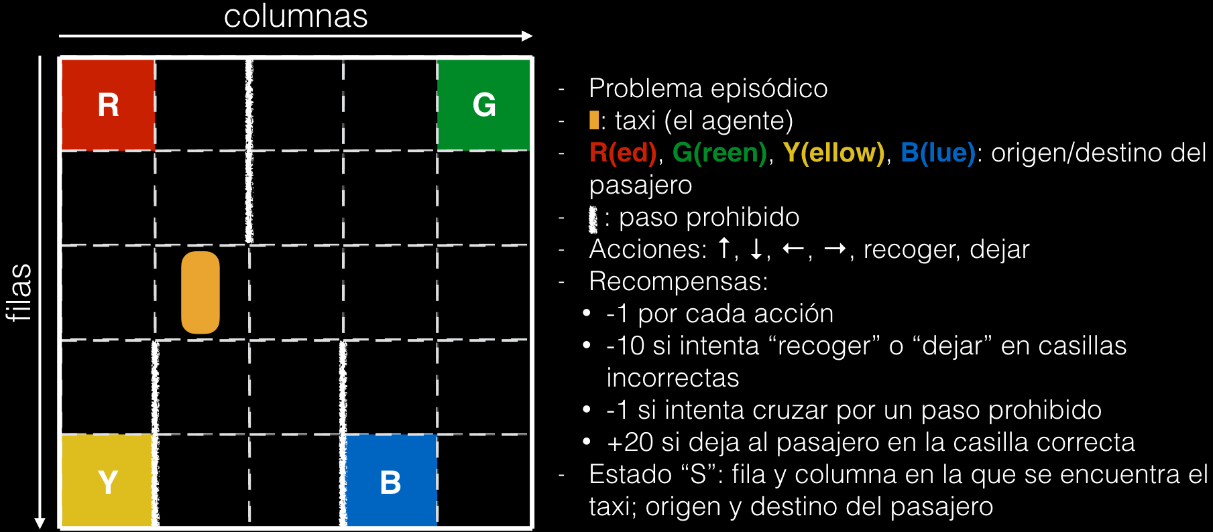

In [1]:
# Se requiere la versión 0.23.1 de OpenAI Gym para poder
# usar el método "render". Versiones más recientes no
# funcionan con Google Colab
!pip install gym==0.23.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 626.2/626.2 kB 7.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gym: filename=gym-0.23.1-py3-none-any.whl size=701463 sha256=21c3ba933ff1e9a6789ab572443e4d4383a02b346a60785710587f80f8b0308e
  Stored in directory: /root/.cache/pip/wheels/83/25/9f/b43a102579ef9977f964a65224424a041e5fa307f61eec8dbc
Successfully built gym
  Attempting uninstall: gym
    Found existing installation: gym 0.25.2
    Uninstalling gym-0.25.2:
      Successfully uninstalled gym-0.25.2


In [2]:
import gym

import numpy as np

import matplotlib.pyplot as plt


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# Crear el entorno y visualizar sus características
env = gym.make("Taxi-v3")
S = env.reset()
env.render()

print('Estado inicial: {}'.format(S))
print('Número de estados: {}'.format(env.observation_space.n))
print('Número de acciones: {}'.format(env.action_space.n))

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+

Estado inicial: 121
Número de estados: 500
Número de acciones: 6


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
def mostrar_estado(env, S):
    '''Imprime en pantalla el estado actual (ubicación del taxi,
    destino y origen)

    Parámetros:
    - env: el entorno de OpenAI Gym
    - S: el estado actual codificado
    '''

    # Decodificar el estado
    tx_fil, tx_col, origen, destino = env.env.decode(S)

    # Diccionarios
    origenes = {0: 'R(ed)', 1: 'G(reen)', 2: 'Y(ellow)', 3: 'B(lue)', 4:'In taxi'}
    destinos = {0: 'R(ed)', 1: 'G(reen)', 2: 'Y(ellow)', 3: 'B(lue)'}

    # Imprimir información en pantalla
    print(f'Ubicación del taxi (fil, col): {tx_fil+1, tx_col+1}')
    print(f'Origen: {origenes[origen]}')
    print(f'Destino: {destinos[destino]}')

# -----------------------------------------------------
def inicializar_Q(nS, nA, tipo='ones'):
    '''
    Inicializar la función Q(S,A) a valores iguales a 1.

    Parámetros:
    - nS: número de estados
    - nA: número de acciones

    Retorna la matriz Q(S,A)
    '''
    if tipo == 'ones':
    	Q = np.ones((nS,nA))
    elif tipo == 'random':
    	Q = np.random.rand(nS,nA)

    return Q

# -----------------------------------------------------
def e_greedy(s, Q, e, nA):
    '''
    Para un estado "s" selecciona una acción proveniente de Q(S,A) usando el enfoque e-greedy

    Parámetros:
    - s: el estado para el cual se desea obtener la acción
    - Q(S,A): tabla Q con S estados y A acciones
    - e: valor de épsilon (entre 0 y 1)
    - nA: número de acciones

    Retorna la acción seleccionada
    '''

    if np.random.rand() >= e:
        # Tomar la mejor acción con una probabilidad 1-e
        accion = np.argmax(Q[s, :])
    else:
        # Tomar cualquier acción aleatoriamente (con probabilidad e)
        accion = np.random.randint(0, nA)

    return accion

# -----------------------------------------------------

In [5]:
# El estado se encuentra codificado, así que usaremos
# la función "mostrar_estado" para decodificarlo e
# imprimir la información en pantalla
mostrar_estado(env, S)

Ubicación del taxi (fil, col): (2, 2)
Origen: R(ed)
Destino: G(reen)


In [6]:
# Interacción
acciones = {0: 'abajo', 1: 'arriba', 2: 'derecha',
            3: 'izquierda', 4: 'recoger', 5: 'dejar'}

A = env.action_space.sample()
S, R, done, info = env.step(A)
env.render()

print(f'Acción seleccionada: {acciones[A]}')
mostrar_estado(env,S)
print(f'Recompensa obtenida: {R}')
print(f'¿Terminó el episodio?: {done}')

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)
Acción seleccionada: recoger
Ubicación del taxi (fil, col): (2, 2)
Origen: R(ed)
Destino: G(reen)
Recompensa obtenida: -10
¿Terminó el episodio?: False


Antes de ver la implementación, veamos dos de las funciones auxiliares:
- `inicializar_Q` que permite inicializar la tabla Q (función acción-valor)
- `e_greedy` que permite seleccionar una acción de la tabla Q usando un enfoque $\epsilon$-greedy

In [7]:
# Prueba de la función "inicializar_Q"
Q = inicializar_Q(6,3, tipo='ones')
print(Q.shape)
print(Q)

Q = inicializar_Q(6,3, tipo='random')
print(Q.shape)
print(Q)

(6, 3)
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
(6, 3)
[[0.42360655 0.84466708 0.4242484 ]
 [0.40914276 0.64041887 0.13129872]
 [0.31718972 0.51691897 0.05902391]
 [0.12471823 0.25070208 0.15629876]
 [0.08721251 0.70357254 0.23753632]
 [0.85832141 0.30410404 0.61230262]]


En realidad, no interesa el tipo de inicialización a usar, pues tarde o temprano tanto SARSA como Q-learning llegarán a la función Q (y política) óptima.

Con el fin de comparar los dos algoritmos realizamos la inicialización tipo `ones`.

Veamos ahora la función `e_greedy`:

In [8]:
# Prueba para el estado s=5
s = 5
e = 0.2 # La mejor acción tendrá una prob. de 1-e de ser seleccionada
a = e_greedy(s,Q,e,3) #Estados, posibles acciones...
print(f'Tabla Q para s={s}: {Q[s,:]}')
print(f'Acción seleccionada para e={e}: {a}')

Tabla Q para s=5: [0.85832141 0.30410404 0.61230262]
Acción seleccionada para e=0.2: 0


##Predicción


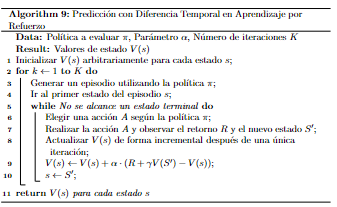

##Control

###Conceptos generales:

Se utiliza la función acción-vaor $Q_\pi(s, a)$ para encontrar una política óptima.

Se busca una combinación entre **Explotación y Exploración**


*   **Explotación:**

Tomamos la acción que maximiza la función:

$ \pi(a|s) = \arg\max_a Q_\pi(s, a)$

Desventaja: Al generar un número finito de escenarios, no podemos garantizar que se visiten todas las acciones posibles. De esta manera, la maximización de esta función no necesariamente es la mejor posible.


*   **Exploración:**

Escoger una acción de manera aleatoria y comenzar a mejorar iterativamente

---------------------------------------------------------------------------
De esta manera surgen los algoritmos codiciosos o *$ \epsilon$ greedy* para balancear explotación y exploración.

Estimar la función acción-valor (Q), y para cada par estado-acción, escoger la acción más adecuada.

*$ \epsilon$ greedy* Indicará la probabilidad de tomar ó el máximo valor de la función para ese estado en particular, o bien abrir la posibilidad a que se tomen cualquiera de las demás acciones disponibles.

---------------------------------------------------------------------------
**Tipos de control:**

*   on-policy:

Utilizamos la misma política que estamos optimizando para definir las acciones del agente

*   off-policy

Se utilizan dos políticas diferentes: una define el comportamiento del agente (cómo va a interactuar el agente con el entorno) y otra para optimizar iterativamente



###SARSA (on-policy)




El algoritmo SARSA actualiza el valor de Q para mejorar la política en función de la experiencia.

$
Q(s, a) \leftarrow Q(s, a) + \alpha \cdot [R + \gamma \cdot Q(s', a') - Q(s, a)]
$

Donde:
- \($Q(s, a$)\) es el valor del estado-acción.
- \($\alpha$) es la tasa de aprendizaje.
- \($R$) es la recompensa.
- \($\gamma$) es el factor de descuento.
- \($s'$) es el nuevo estado.
- \($a'$) es la nueva acción.

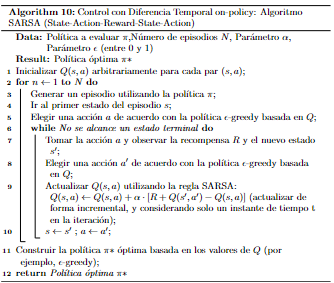

In [9]:
# -----------------------------------------------------
def sarsa(env, alpha, gamma, epsilon, nS, nA, K, verbose=False):
    '''
    Algoritmo de control SARSA

    Parámetros:
    - env: el entorno
    - alpha: la tasa de aprendizaje (entre 0 y 1)
    - gamma: factor de descuento (entre 0 y 1)
    - epsilon: parámetro para el algoritmo e-greedy (entre 0 y 1)
    - nS, nA: número de estados y de acciones
    - K: número de episodios a generar
    - verbose: imprimir en pantalla el progreso del entrenamiento (por defecto falso)
    '''

    # Inicializar Q(S,A) y almacenar retorno (la evolucion del entrenamiento)
    Q = inicializar_Q(nS, nA)
    retorno = []

    # Correr K episodios de interacción y estimar Q(S,A)
    for episodio in range(K):
        # Inicializar retorno acumulado
        retorno_acumulado = 0

        # Ir al primer estado del episodio
        s = env.reset()

        # Elegir acción usando e-greedy
        a = e_greedy(s, Q, epsilon, nA)

        done = False # Aún no estamos en un estado terminal

        while not done:
            # Iniciar interacciones y actualizar función Q
            s_, r_, done, info = env.step(a)
            a_ = e_greedy(s_, Q, epsilon, nA)
            retorno_acumulado += r_

            if not done:
                # Actualizar Q si no es un episodio terminal
                Q[s, a] += alpha * ( r_ + (gamma * Q[s_, a_] ) - Q[s, a] )
            else:
                # Si el episodio es terminal no se añade gamma * Q[S_, a_]
                # (porque Q[s_, a_] = 0 por ser estado terminal)
                Q[s, a] += alpha * ( r_ - Q[s, a] )
                retorno.append(retorno_acumulado)

            # Actualizar el estado y la acción
            s, a = s_, a_

            # Imprimir información cada 100 episodios
            if verbose:
                if episodio%100 == 0:
                    print(f'Episodio: {episodio+1}/{K}:')
                    print(f'\t\tRecompensa: {r_}')


    # Al finalizar tendremos la tabla Q, que implícitamente
    # contendrá la política
    return Q, retorno

# -----------------------------------------------------

Entrenemos el agente con el algoritmo SARSA. Para ello usaremos la función `sarsa`, definiendo inicialmente los **hiperparámetros** sin un criterio en particular:

In [10]:
# Hiperparámetros
ALPHA = 0.4
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
K = 2000

# Número de estados/acciones
NS = env.observation_space.n
NA = env.action_space.n

Q_s, ret_s = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

Veamos cuál ha sido el progreso del entrenamiento. La idea es que al comienzo el retorno obtenido (`ret_s`) debe ser bajo (valores negativos) y a medida que progresa este valor debería ser más alto (es decir cercano a cero):

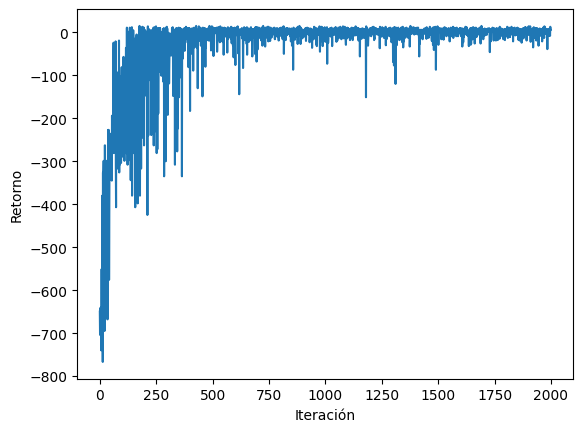

In [11]:
plt.plot(ret_s)
plt.xlabel('Iteración');
plt.ylabel('Retorno');

Se cumple con lo mencionado anteriormente.

Pero ¿será que podemos mejorar este desempeño? La respuesta es sí, y para esto debemos realizar un **ajuste de los hiperparámetros**.

####Ajuste de Hiperparámetros

Este ajuste se debe hacer de forma sistemática, es decir modificando sólo uno de ellos, dejando los demás fijos, y observando si mejora/empeora el entrenamiento

In [12]:
# -----------------------------------------------------
def graficar_entrenamiento(retornos, titulos):

    # Generar figura
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 6),
    	sharex=True, sharey=True)

    # Graficar
    ax1.plot(retornos[0])
    ax1.title.set_text(titulos[0])
    ax2.plot(retornos[1], 'tab:orange')
    ax2.title.set_text(titulos[1])
    ax3.plot(retornos[2], 'tab:green')
    ax3.title.set_text(titulos[2])
    ax4.plot(retornos[3], 'tab:red')
    ax4.title.set_text(titulos[3])

    # Etiquetar ejes
    plt.setp([ax3, ax4], xlabel='Iteración')
    plt.setp([ax1, ax3], ylabel='Retorno')
    # -----------------------------------------------------

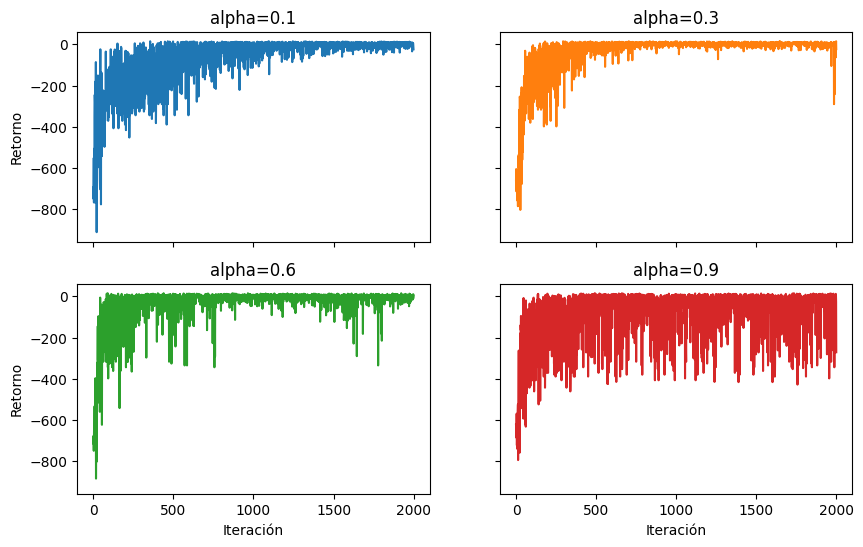

In [13]:
# Entrenamiento con diferentes tasas de aprendizaje (ALPHA)
Q_s1, ret_s1 = sarsa(env, 0.1, GAMMA, EPSILON, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, 0.3, GAMMA, EPSILON, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, 0.6, GAMMA, EPSILON, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, 0.9, GAMMA, EPSILON, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['alpha=0.1', 'alpha=0.3', 'alpha=0.6', 'alpha=0.9']
graficar_entrenamiento(retornos, titulos)

Al parecer un ALPHA=0.3 resulta adecuado, porque con menos iteraciones logra estabilizarse (llegar casi a cero) más rápido el retorno obtenido.

Dejaremos fijo este hiperparámetro y nos enfocaremos ahora en K (el número de episodios usados en el entrenamiento):

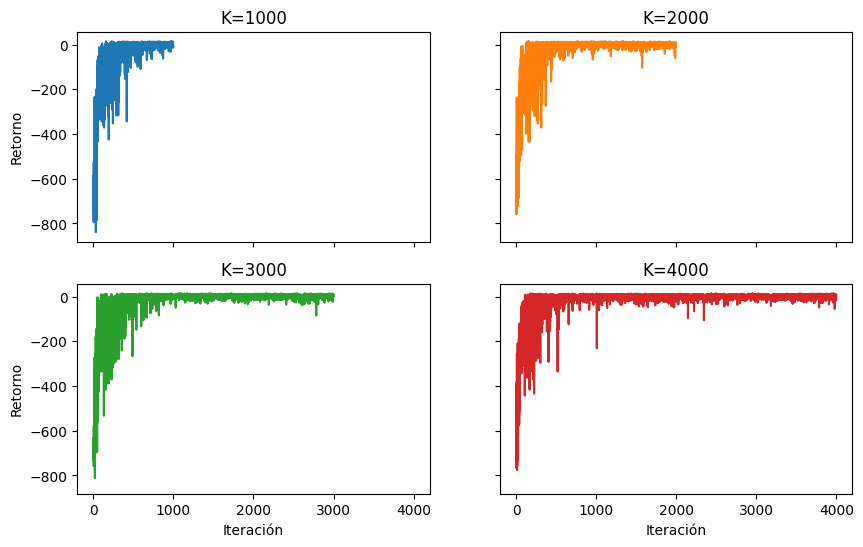

In [14]:
# Entrenamiento con diferentes Ks
ALPHA = 0.35
Q_s1, ret_s1 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 1000)
Q_s2, ret_s2 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 2000)
Q_s3, ret_s3 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 3000)
Q_s4, ret_s4 = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, 4000)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['K=1000', 'K=2000', 'K=3000', 'K=4000']
graficar_entrenamiento(retornos, titulos)

No parece haber mucha diferencia entre uno y otro valor. Dado que el entrenamiento es relativamente rápido, usaremos K = 3000.

Ahora ajustaremos el hiperparámetro  ϵ :

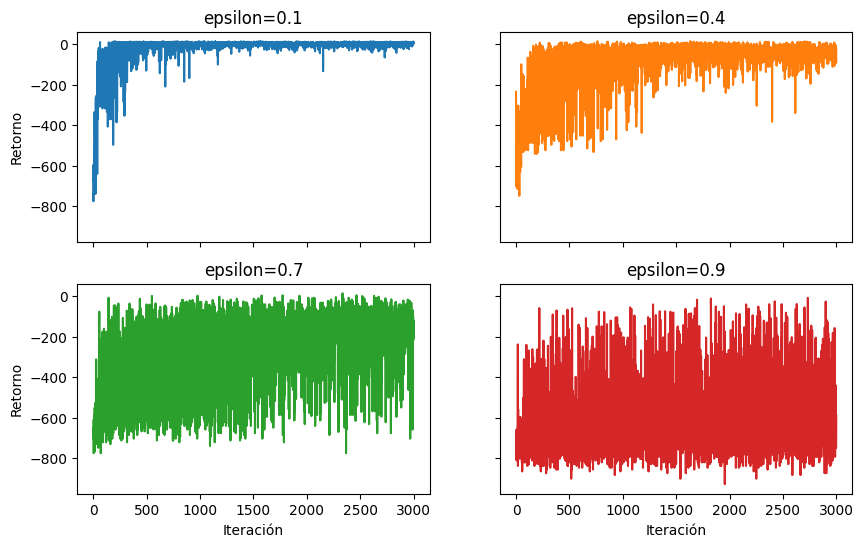

In [15]:
K = 3000

# Entrenamiento con diferentes epsilon
Q_s1, ret_s1 = sarsa(env, ALPHA, GAMMA, 0.1, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, ALPHA, GAMMA, 0.4, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, ALPHA, GAMMA, 0.7, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, ALPHA, GAMMA, 0.9, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['epsilon=0.1', 'epsilon=0.4', 'epsilon=0.7', 'epsilon=0.9']
graficar_entrenamiento(retornos, titulos)

El resultado anterior tiene lógica, pues entre mayor sea  ϵ  mayor importancia estaremos dando a la exploración (es decir a acciones seleccionadas aleatoriamente) y menor a la explotación.

Así que ajustaremos  ϵ  en 0.1 y nos enfocaremos en el último hiperparámetro:  γ  (el factor de descuento):

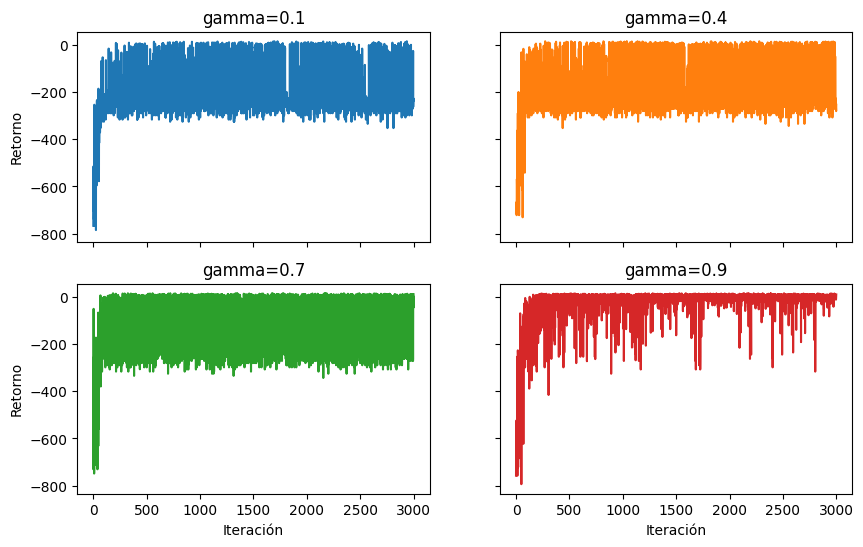

In [16]:
EPSILON = 0.1

# Entrenamiento con diferentes gamma
Q_s1, ret_s1 = sarsa(env, ALPHA, 0.1, EPSILON, NS, NA, K)
Q_s2, ret_s2 = sarsa(env, ALPHA, 0.4, EPSILON, NS, NA, K)
Q_s3, ret_s3 = sarsa(env, ALPHA, 0.7, EPSILON, NS, NA, K)
Q_s4, ret_s4 = sarsa(env, ALPHA, 0.9, EPSILON, NS, NA, K)

# Curvas de entrenamiento resultantes
retornos = [ret_s1, ret_s2, ret_s3, ret_s4]
titulos = ['gamma=0.1', 'gamma=0.4', 'gamma=0.7', 'gamma=0.9']
graficar_entrenamiento(retornos, titulos)

Observamos que entre más alto sea el valor de $\gamma$ más importancia le daremos al comportamiento futuro y menos a la acción presente y por tanto mejorará la interacción.

Así que usaremos un $\gamma$ lo más cercano posible a 1 (0.999) y entrenaremos el agente con los hiperparámetros ajustados:

- ALPHA = 0.3
- GAMMA = 0.999
- EPSILON = 0.1
- K = 4000

In [17]:
GAMMA = 0.999

Q_s, ret_s = sarsa(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

De esta manera, el agente ya está entrenado.

Al final de la práctica veremos cómo usar la tabla Q obtenida para generar interacciones. Pero antes veamos cómo realizar el entrenamiento con el algoritmo Q-learning.

###Q-Learning (off-policy")



El algoritmo Q-learning busca el valor óptimo de Q para encontrar la política óptima.

$
Q(s, a) \leftarrow Q(s, a) + \alpha \cdot [R + \gamma \cdot \max_a Q(s', a) - Q(s, a)]
$

Donde:
- \($Q(s, a$)\) es el valor del estado-acción.
- \($\alpha$) es la tasa de aprendizaje.
- \($R$) es la recompensa.
- \($\gamma$) es el factor de descuento.
- \($s'$) es el nuevo estado.
- \($a'$) es la nueva acción.
- \($max_a$) toma el valor óptimo para el siguiente estado.

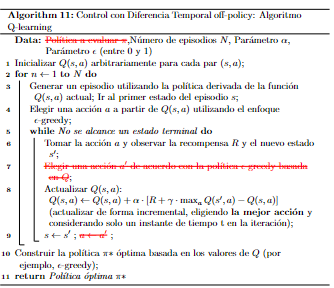

In [18]:
# -----------------------------------------------------
def qlearning(env, alpha, gamma, epsilon, nS, nA, K, verbose=False):
    '''
    Algoritmo de control Q-learning

    Parámetros:
    - env: el entorno
    - alpha: la tasa de aprendizaje (entre 0 y 1)
    - gamma: factor de descuento (entre 0 y 1)
    - epsilon: parámetro para el algoritmo e-greedy
    - nS, nA: número de estados y de acciones
    - K: número de episodios a generar
    - verbose: imprimir en pantalla el progreso del entrenamiento (por defecto falso)
    '''

    # Inicializar Q(S,A) y almacenar retorno (la evolución del entrenamiento)
    Q = inicializar_Q(nS, nA)
    retorno = []

    # Correr K episodios de interacción y estimar Q(S,A)
    for episodio in range(K):
        # Inicializar retorno total
        retorno_acumulado = 0

        # Ir al primer estado del episodio
        s = env.reset()

        # Elegir acción usando e-greedy
        a = e_greedy(s, Q, epsilon, nA)

        done = False # Aún no estamos en un estado terminal

        while not done:
            # Iniciar interacciones y actualizar función Q
            s_, r_, done, info = env.step(a)
            a_ = np.argmax(Q[s_, :]) # <---- ESTA ES LA DIFERENCIA CON SARSA
            retorno_acumulado += r_

            if not done:
                # Si no es un episodio terminal, actualizar Q
                Q[s, a] += alpha * ( r_ + (gamma * Q[s_, a_] ) - Q[s, a] )
            else:
                # Si el episodio es terminal no se añade gamma * Q[S_, a_]
                # (porque Q[s_, a_] = 0 por ser estado terminal)
                Q[s, a] += alpha * ( r_ - Q[s, a] )
                retorno.append(retorno_acumulado)

            # Actualizar el estado y la acción
            s, a = s_, a_

            # Imprimir información cada 100 episodios
            if verbose:
                if episodio%100 == 0:
                    print(f'Episodio: {episodio+1}/{K}:')
                    print(f'\t\tRecompensa final: {r_}')


    # Al finalizar tendremos la tabla Q, que implícitamente
    # contendrá la política
    return Q, retorno

# -----------------------------------------------------

Seguiremos la misma lógica usada para el control con SARSA para llevar a cabo el entrenamiento de nuestro agente usando el algoritmo Q-learning.

En este caso usaremos la funcion `q_learning` que implementa este algoritmo:

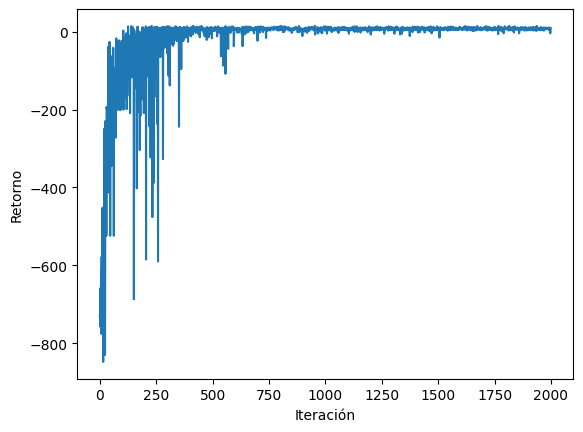

In [19]:
# Prueba del algoritmo Q-learning usando un set arbitrario
# de hiperparámetros
ALPHA = 0.4
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
NS = env.observation_space.n
NA = env.action_space.n
K = 2000

Q_ql, ret_ql = qlearning(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

# Y grafiquemos la curva de entrenamiento
plt.plot(ret_ql)
plt.xlabel('Iteración');
plt.ylabel('Retorno');

####Ajuste de Hiperparámetros

De nuevo, al igual que con SARSA, en este caso debemos hacer un ajuste de hiperparámetros.

Así que, si seguimos el mismo procedimiento de antes, llegaremos a este set:

- ALPHA = 0.6
- GAMMA = 0.999
- EPSILON = 0.1
- K = 4000

Entrenemos nuestro agente con estos hiperparámetros:

In [20]:
ALPHA = 0.6
GAMMA = 0.999
EPSILON = 0.1 # (Probabilidad de escoger mejor acción = 1-0.1 = 0.9)
K = 4000

Q_ql, ret_ql = qlearning(env, ALPHA, GAMMA, EPSILON, NS, NA, K)

###Comparación



Ahora sí, con el agente entrenado usando los dos métodos, intentemos ver cuál de ellos tiene el mejor desempeño.

Para ello podemos simplemente graficar las curvas de entrenamiento obtenidas en cada caso:

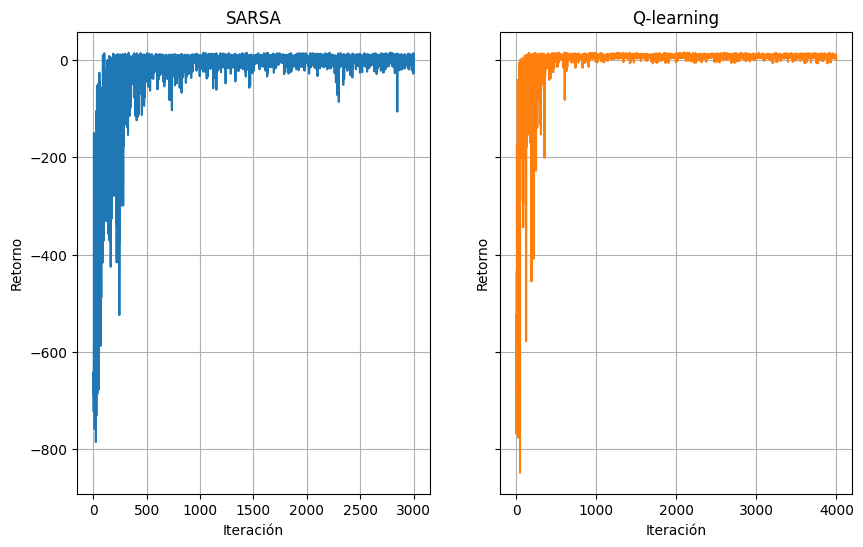

In [21]:
fig, ((ax1, ax2)) = plt.subplots(1, 2, figsize=(10, 6), sharey=True)

# Graficar
ax1.plot(ret_s)
ax1.title.set_text('SARSA')
ax1.set_xlabel('Iteración')
ax1.grid(True)

ax2.plot(ret_ql, 'tab:orange')
ax2.title.set_text('Q-learning')
ax2.set_xlabel('Iteración')
ax2.grid(True)

plt.setp([ax1, ax2], ylabel='Retorno');

Vemos que la convergencia de Q-learning es significativamente más rápida que SARSA: en la iteración 1.000 (aprox.) ya se estabiliza el primero y su retorno ya es positivo, mientras que para esa misma iteración SARSA aún no se estabiliza (de hecho en la iteración 4.000 su retorno sigue siendo negativo en ocasiones).

Esto confirma que Q-learning permite entrenar el agente de forma adecuada y con un menor número de iteraciones en comparación con SARSA.

Ahora sí, hacemos que el agente interactúe con el entorno

##Interacción

In [22]:
# -----------------------------------------------------
def interaccion(env, Q, method=None):
    it = 0
    s = env.reset()

    print('Resultado de la interacción:')
    print('-'*60)
    print('-'*60)

    # Imprimir estado y entorno iniciales
    print('**** Entorno-agente al inicio: ****')
    env.render()
    _, _, _, dest_i = env.env.decode(s)
    mostrar_estado(env, s)

    print('\nInteractuando...\n')

    # Hacer que el agente interactúe con el entorno tomando como política
    # el máximo de la función Q para cada estado
    a = np.argmax(Q[s,:]) # ¡La política!
    done = False

    # Interactuar hasta llegar a un estado terminal
    while not done:
        it += 1
        # Iniciar interacciones y actualizar función Q
        s, r, done, info = env.step(a)
        a = np.argmax(Q[s, :])

    # Imprimir información final
    _, _, _, dest_f = env.env.decode(s)
    if dest_i == dest_f:
        print(f'\nEl episodio culminó ***EXITOSAMENTE*** en {it} iteraciones')
    else:
        print(f'\nEl episodio culminó en {it} iteraciones')

    print('**** Entorno-agente al final: ****')
    env.render()
    mostrar_estado(env, s)
    print(f'Recompensa obtenida: {r}')

# -----------------------------------------------------

In [23]:
#interaccion(env,Q_ql)
interaccion(env,Q_s)

Resultado de la interacción:
------------------------------------------------------------
------------------------------------------------------------
**** Entorno-agente al inicio: ****
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+

Ubicación del taxi (fil, col): (5, 3)
Origen: B(lue)
Destino: Y(ellow)

Interactuando...


El episodio culminó ***EXITOSAMENTE*** en 16 iteraciones
**** Entorno-agente al final: ****
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)
Ubicación del taxi (fil, col): (5, 1)
Origen: Y(ellow)
Destino: Y(ellow)
Recompensa obtenida: 20


# **Trabajo Práctico**

**PARTE 3: DIFERENCIA TEMPORAL: SARSA Y Q-LEARNING (Unidad 3)**

A partir del Google Colab suministrado UGR_AR_3_DiferenciaTemporalOpenAIGym_TA1
generar el código para:

* Ajustar los hiperparámetros de los algoritmos SARSA y Q-Learning evaluando:
○ ALPHA: 0.1, 0.2, 0.3 y 0.4
○ GAMMA: 0.99, 0.95, 0.90 y 0.85
○ EPSILON: 0.05, 0.1, 0.15 y 0.2
○ K: 100, 1000, 5000, 10000 (Considerar la variable costo computacional)

* Iterar al menos 1000 veces la interacción del agente con el entorno con cada uno de
los algoritmos

*  Para cada uno, guardar el resultado del timestep (cuántas acciones le toma llegar a
un estado terminal en cada iteración).

* Para cada uno, elaborar un indicador del porcentaje de éxito (cuántas veces llega el
agente a la meta sobre la cantidad de veces que lo intentó) y de la cantidad de
timestep promedio para todas las iteraciones (mostrar este resultado en un gráfico o
tabla).

* Indicar cuál de los dos algoritmos presenta mejores resultados. Justificar gráfica y
analíticamente.

**ENTREGABLES:**

1. Google Colab con la memoria del trabajo realizado (código + descripción/comentarios)

Nota: Los archivos se deben nombrar cómo: AAAANC_UGR_AR_TP2_ApellidoNombre
AAAA = AÑO
N = CUATRIMESTRE {1,2}


##  Diferencia Temporal: SARSA y Q-Learning

En esta parte del trabajo se evaluarán los algoritmos SARSA y Q-Learning en el entorno Taxi-v3 de OpenAI Gym.

Se analizará el efecto de los hiperparámetros ALPHA, GAMMA, EPSILON y K sobre el aprendizaje del agente. Para comparar los algoritmos se registrará la cantidad de acciones o timesteps de cada episodio, el porcentaje de éxito y el promedio de timesteps.

Finalmente, se compararán los resultados obtenidos para determinar qué algoritmo presenta un mejor desempeño en las pruebas realizadas.

**1. Código para medir cada episodio**

Esta celda reutiliza el entorno env de Taxi-v3 y registra los timesteps y los éxitos que necesitamos para el TP.

**Aclaración sobre los timesteps por episodio y la forma de medir**

Para limitar la duración de cada episodio, se estableció un máximo de 200 acciones. Si el agente no alcanza el estado terminal dentro de ese límite, el episodio se registra con 200 timesteps y se contabiliza como no exitoso.

Se miden **dos cosas** distintas:
* **Durante el entrenamiento** (con exploración ε-greedy y la tabla Q todavía aprendiendo): es lo que pide la consigna al guardar los timesteps de cada iteración.
* **Evaluación greedy posterior** (ε = 0, tabla Q ya entrenada, 1.000 episodios): mide el desempeño real de la política aprendida, sin el sesgo de los primeros episodios de aprendizaje ni de la exploración.

Además se mide el **tiempo de cómputo** de cada entrenamiento (variable costo computacional pedida para K) y se fija una **semilla** para que los resultados sean reproducibles.

*Nota:* a diferencia de la función `qlearning` del Colab base (que elige la acción siguiente de forma greedy), aquí Q-Learning usa ε-greedy como política de comportamiento y max Q sólo en la actualización, que es la definición off-policy correcta.

In [24]:
import time
import pandas as pd


def elegir_accion(estado, Q, epsilon, nA):
    return e_greedy(estado, Q, epsilon, nA)


def entrenar_y_medir(env, algoritmo, alpha, gamma, epsilon, K,
                     max_steps=200, seed=None):
    """Entrena SARSA o Q-Learning y registra, por episodio, los
    timesteps y si llegó a la meta. Devuelve (Q, DataFrame, segundos)."""

    if seed is not None:
        np.random.seed(seed)      # para e-greedy
        env.reset(seed=seed)      # para el entorno

    t0 = time.time()
    nS = env.observation_space.n
    nA = env.action_space.n
    Q = inicializar_Q(nS, nA)
    registros = []

    for episodio in range(K):
        estado = env.reset()
        accion = elegir_accion(estado, Q, epsilon, nA)

        terminado = False
        pasos = 0
        recompensa_final = 0

        while not terminado and pasos < max_steps:
            siguiente_estado, recompensa, done, info = env.step(accion)
            pasos += 1
            recompensa_final = recompensa

            # Se limita la duración del episodio a max_steps
            fin = done or pasos >= max_steps

            if algoritmo == "SARSA":
                if not fin:
                    siguiente_accion = elegir_accion(
                        siguiente_estado, Q, epsilon, nA)
                    objetivo = recompensa + gamma * Q[
                        siguiente_estado, siguiente_accion]
                else:
                    objetivo = recompensa
                Q[estado, accion] += alpha * (objetivo - Q[estado, accion])
                if not fin:
                    estado = siguiente_estado
                    accion = siguiente_accion

            elif algoritmo == "Q-Learning":
                if fin:
                    objetivo = recompensa
                else:
                    objetivo = recompensa + gamma * np.max(
                        Q[siguiente_estado, :])
                Q[estado, accion] += alpha * (objetivo - Q[estado, accion])
                if not fin:
                    estado = siguiente_estado
                    accion = elegir_accion(estado, Q, epsilon, nA)
            else:
                raise ValueError("Algoritmo no reconocido")

            terminado = fin

        registros.append({
            "episodio": episodio + 1,
            "timesteps": pasos,
            "recompensa_final": recompensa_final,
            "exito": recompensa_final == 20
        })

    segundos = time.time() - t0
    return Q, pd.DataFrame(registros), segundos


def evaluar_greedy(env, Q, episodios=1000, max_steps=200):
    """Evalúa la política aprendida (epsilon = 0) sin modificar Q.
    Devuelve (% de éxito, timesteps promedio)."""
    exitos, pasos_total = 0, 0
    for _ in range(episodios):
        s = env.reset()
        pasos, r, done = 0, 0, False
        while not done and pasos < max_steps:
            s, r, done, _ = env.step(int(np.argmax(Q[s, :])))
            pasos += 1
        exitos += (r == 20)
        pasos_total += pasos
    return 100 * exitos / episodios, pasos_total / episodios




/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* timesteps: cuenta las acciones ejecutadas durante cada episodio.



* exito: considera exitoso el episodio cuando el agente recibe la recompensa de 20, correspondiente a completar correctamente el objetivo en Taxi-v3.



* SARSA: actualiza la tabla Q utilizando la acción siguiente elegida por la política.



* Q-Learning: utiliza el mayor valor Q disponible para el siguiente estado.



* max_steps=200: evita que un episodio quede ejecutándose indefinidamente.



**2. Función para calcular los indicadores**

Esta funcion calcula el porcentaje de éxito y el promedio de timesteps, que son dos resultados centrales de la consigna.

In [25]:

def resumir_resultados(datos):
    intentos = len(datos)
    exitos = datos["exito"].sum()

    porcentaje_exito = 100 * exitos / intentos
    promedio_timesteps = datos["timesteps"].mean()

    return {
        "intentos": intentos,
        "exitos": int(exitos),
        "porcentaje_exito": round(porcentaje_exito, 2),
        "promedio_timesteps": round(promedio_timesteps, 2)
    }


Por ejemplo, si en 1.000 episodios el agente llega a la meta 800 veces, su porcentaje de éxito será del 80 %. El promedio de timesteps se calcula con los episodios realizados, no solamente con los exitosos.

**3. Evaluar los cuatro hiperparámetros**

Se analizarán los valores indicados en la consigna para cada algoritmo. Para estudiar el efecto de cada hiperparámetro se modificarán sus valores manteniendo constantes los restantes. En las pruebas de ALPHA, GAMMA y EPSILON se utilizarán 1.000 episodios por configuración. Para K se evaluarán las cantidades 100, 1.000, 5.000 y 10.000 episodios, considerando también el costo computacional.

**Aclaración:** Aunque la consigna establece un mínimo de 1.000 episodios por algoritmo, se incluye K = 100 como prueba específica de ajuste de hiperparámetros, tal como se solicita. Las evaluaciones principales y la comparación final se realizan con al menos 1.000 episodios por algoritmo.

In [26]:
# Valores solicitados en la consigna
valores_alpha = [0.1, 0.2, 0.3, 0.4]
valores_gamma = [0.99, 0.95, 0.90, 0.85]
valores_epsilon = [0.05, 0.1, 0.15, 0.2]
valores_K = [100, 1000, 5000, 10000]

# Configuración de referencia
base = {"alpha": 0.3, "gamma": 0.99, "epsilon": 0.1, "K": 1000}
SEMILLA = 42

resultados_pruebas = []
registros_timesteps = []


def probar_parametro(algoritmo, nombre, valores):
    resultados = []

    for valor in valores:
        config = base.copy()
        config[nombre] = valor

        Q, datos, segundos = entrenar_y_medir(
            env, algoritmo,
            config["alpha"], config["gamma"], config["epsilon"], config["K"],
            seed=SEMILLA)

        resumen = resumir_resultados(datos)
        resumen["algoritmo"] = algoritmo
        resumen["parametro"] = nombre.upper()
        resumen["valor"] = valor
        resumen["segundos"] = round(segundos, 2)


        # Evaluación de la política final (epsilon = 0)
        exito_g, pasos_g = evaluar_greedy(env, Q)
        resumen["exito_greedy"] = round(exito_g, 2)
        resumen["timesteps_greedy"] = round(pasos_g, 2)
        resultados.append(resumen)

        # Guardar el timestep de cada episodio de esta configuración
        for fila in datos.itertuples():
            registros_timesteps.append({
                "algoritmo": algoritmo, "parametro": nombre.upper(),
                "valor": valor, "episodio": fila.episodio,
                "timesteps": fila.timesteps, "exito": bool(fila.exito),
                "recompensa_final": fila.recompensa_final,
                "alpha": config["alpha"], "gamma": config["gamma"],
                "epsilon": config["epsilon"], "K": config["K"]})

        print(f"{algoritmo} {nombre}={valor} | Éxito: {resumen['porcentaje_exito']:.2f} % "
              f"| Timesteps: {resumen['promedio_timesteps']:.2f} "
              f"| Greedy: {exito_g:.2f} % / {pasos_g:.2f} pasos "
              f"| {segundos:.2f} s")

    return pd.DataFrame(resultados)


for algoritmo in ["SARSA", "Q-Learning"]:
    for nombre, valores in [("alpha", valores_alpha), ("gamma", valores_gamma),
                            ("epsilon", valores_epsilon), ("K", valores_K)]:
        resultados_pruebas.append(probar_parametro(algoritmo, nombre, valores))

# Tabla resumen de todas las configuraciones
tabla_hiperparametros = pd.concat(resultados_pruebas, ignore_index=True)
display(tabla_hiperparametros.round(2))


# Tabla con los timesteps de cada episodio
tabla_timesteps = pd.DataFrame(registros_timesteps)
print("Cantidad de registros individuales:", len(tabla_timesteps))
display(tabla_timesteps.head(10))



SARSA alpha=0.1 | Éxito: 80.80 % | Timesteps: 91.12 | Greedy: 41.80 % / 121.09 pasos | 1.89 s
SARSA alpha=0.2 | Éxito: 87.90 % | Timesteps: 62.76 | Greedy: 73.20 % / 62.76 pasos | 1.03 s
SARSA alpha=0.3 | Éxito: 90.30 % | Timesteps: 51.85 | Greedy: 77.70 % / 54.55 pasos | 1.51 s
SARSA alpha=0.4 | Éxito: 91.00 % | Timesteps: 46.36 | Greedy: 77.00 % / 56.08 pasos | 0.76 s
SARSA gamma=0.99 | Éxito: 90.30 % | Timesteps: 51.85 | Greedy: 77.70 % / 54.55 pasos | 0.85 s
SARSA gamma=0.95 | Éxito: 89.90 % | Timesteps: 52.89 | Greedy: 77.20 % / 55.59 pasos | 1.24 s
SARSA gamma=0.9 | Éxito: 86.10 % | Timesteps: 62.16 | Greedy: 79.10 % / 52.22 pasos | 1.61 s
SARSA gamma=0.85 | Éxito: 84.40 % | Timesteps: 66.81 | Greedy: 60.10 % / 87.52 pasos | 1.08 s
SARSA epsilon=0.05 | Éxito: 93.00 % | Timesteps: 46.14 | Greedy: 94.50 % / 23.33 pasos | 0.78 s
SARSA epsilon=0.1 | Éxito: 90.30 % | Timesteps: 51.85 | Greedy: 77.70 % / 54.55 pasos | 0.90 s
SARSA epsilon=0.15 | Éxito: 87.70 % | Timesteps: 58.29 | Gree

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,intentos,exitos,porcentaje_exito,promedio_timesteps,algoritmo,parametro,valor,segundos,exito_greedy,timesteps_greedy
0,1000,808,80.80,91.12,SARSA,ALPHA,0.10,1.89,41.8,121.09
1,1000,879,87.90,62.76,SARSA,ALPHA,0.20,1.03,73.2,62.76
2,1000,903,90.30,51.85,SARSA,ALPHA,0.30,1.51,77.7,54.55
3,1000,910,91.00,46.36,SARSA,ALPHA,0.40,0.76,77.0,56.08
4,1000,903,90.30,51.85,SARSA,GAMMA,0.99,0.85,77.7,54.55
5,1000,899,89.90,52.89,SARSA,GAMMA,0.95,1.24,77.2,55.59
6,1000,861,86.10,62.16,SARSA,GAMMA,0.90,1.61,79.1,52.22
7,1000,844,84.40,66.81,SARSA,GAMMA,0.85,1.08,60.1,87.52
8,1000,930,93.00,46.14,SARSA,EPSILON,0.05,0.78,94.5,23.33
9,1000,903,90.30,51.85,SARSA,EPSILON,0.10,0.90,77.7,54.55


Cantidad de registros individuales: 56200


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algoritmo,parametro,valor,episodio,timesteps,exito,recompensa_final,alpha,gamma,epsilon,K
0,SARSA,ALPHA,0.1,1,200,False,-1,0.1,0.99,0.1,1000
1,SARSA,ALPHA,0.1,2,200,False,-1,0.1,0.99,0.1,1000
2,SARSA,ALPHA,0.1,3,200,False,-1,0.1,0.99,0.1,1000
3,SARSA,ALPHA,0.1,4,200,False,-1,0.1,0.99,0.1,1000
4,SARSA,ALPHA,0.1,5,200,False,-1,0.1,0.99,0.1,1000
5,SARSA,ALPHA,0.1,6,200,False,-10,0.1,0.99,0.1,1000
6,SARSA,ALPHA,0.1,7,200,False,-1,0.1,0.99,0.1,1000
7,SARSA,ALPHA,0.1,8,200,False,-1,0.1,0.99,0.1,1000
8,SARSA,ALPHA,0.1,9,200,False,-10,0.1,0.99,0.1,1000
9,SARSA,ALPHA,0.1,10,200,False,-1,0.1,0.99,0.1,1000


**4. Análisis gráfico de los hiperparámetros**

Se grafica, para cada hiperparámetro, el porcentaje de éxito y los timesteps promedio durante el entrenamiento, junto con el desempeño de la política final (ε = 0). Para K se agrega el tiempo de cómputo.

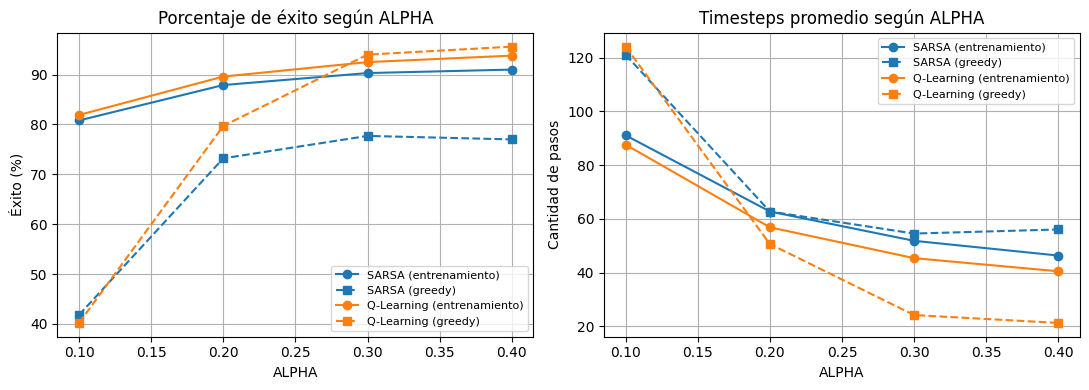

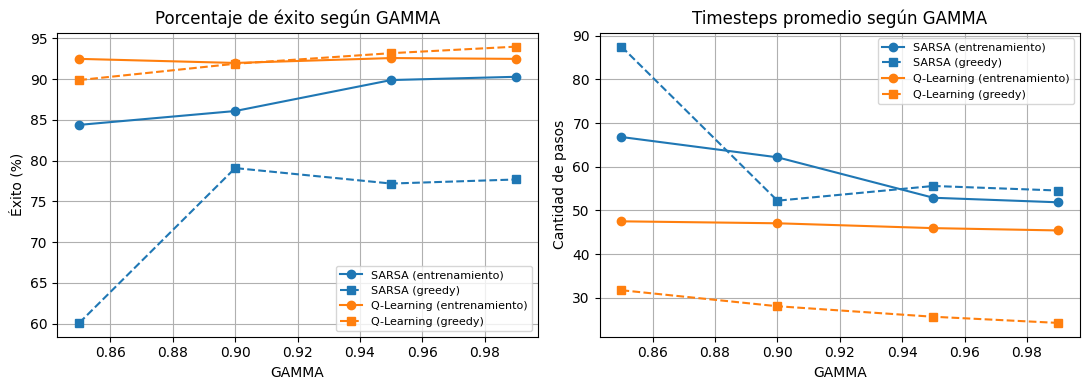

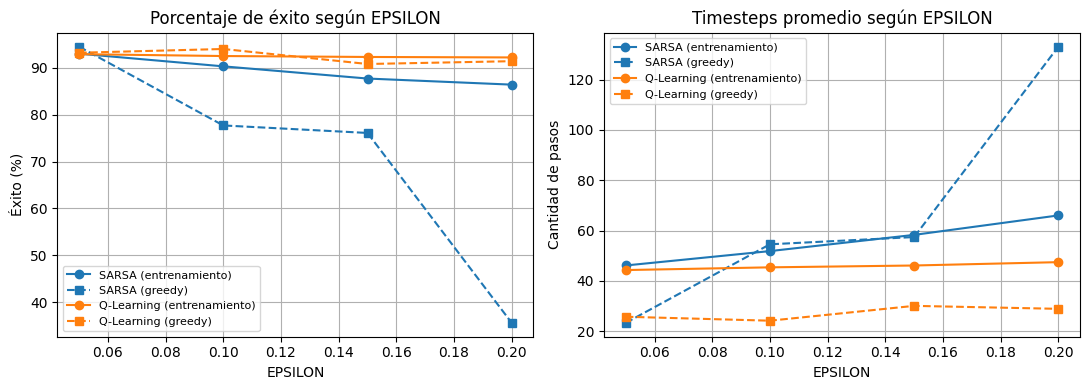

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1984: PyparsingDeprecationWarning: 'setName' deprecated - use 'set_name'
  val.setName(key)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1987: PyparsingDeprecationWarning: 'setParseA

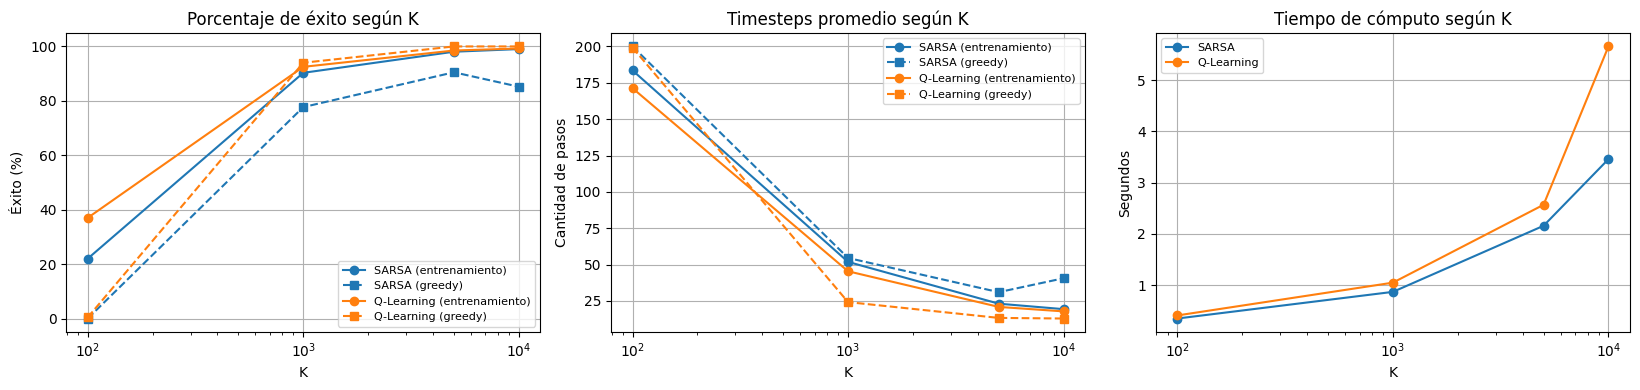

In [27]:
# Un gráfico para cada hiperparámetro
for parametro in ["ALPHA", "GAMMA", "EPSILON", "K"]:

    subset = tabla_hiperparametros[tabla_hiperparametros["parametro"] == parametro]
    ncols = 3 if parametro == "K" else 2
    fig, ejes = plt.subplots(1, ncols, figsize=(5.5 * ncols, 4))

    for algoritmo in ["SARSA", "Q-Learning"]:
        d = subset[subset["algoritmo"] == algoritmo].sort_values("valor")
        p, = ejes[0].plot(d["valor"], d["porcentaje_exito"], marker="o", label=f"{algoritmo} (entrenamiento)")
        ejes[0].plot(d["valor"], d["exito_greedy"], marker="s", linestyle="--",
                     color=p.get_color(), label=f"{algoritmo} (greedy)")
        p, = ejes[1].plot(d["valor"], d["promedio_timesteps"], marker="o", label=f"{algoritmo} (entrenamiento)")
        ejes[1].plot(d["valor"], d["timesteps_greedy"], marker="s", linestyle="--",
                     color=p.get_color(), label=f"{algoritmo} (greedy)")
        if parametro == "K":
            ejes[2].plot(d["valor"], d["segundos"], marker="o", label=algoritmo)

    ejes[0].set_title(f"Porcentaje de éxito según {parametro}")
    ejes[0].set_ylabel("Éxito (%)")
    ejes[1].set_title(f"Timesteps promedio según {parametro}")
    ejes[1].set_ylabel("Cantidad de pasos")
    if parametro == "K":
        ejes[2].set_title("Tiempo de cómputo según K")
        ejes[2].set_ylabel("Segundos")

    for ax in ejes:
        ax.set_xlabel(parametro)
        ax.legend(fontsize=8)
        ax.grid(True)
        if parametro == "K":
            ax.set_xscale("log")


    plt.tight_layout()
    plt.show()

**Análisis de los resultados por hiperparámetro**

Los valores corresponden a una corrida con semilla fija (42). "Entrenamiento" es el desempeño durante el aprendizaje (con exploración) y "greedy" es la política final evaluada con ε = 0 en 1.000 episodios.

| Hiperparámetro | Mejor valor SARSA | Mejor valor Q-Learning | Observación |
|---|---|---|---|
| ALPHA | 0.40 (91.00 % entrenamiento) | 0.40 (93.80 % entrenamiento, 95.60 % greedy) | Con 0.1 ambos aprenden lento (≈ 81 %) |
| GAMMA | 0.99 (90.30 %) | 0.99 (94.00 % greedy) | Q-Learning empeora de forma gradual al bajar γ; SARSA es más irregular |
| EPSILON | 0.05 (93.00 %, 94.50 % greedy) | 0.05 y 0.10 (similares) | SARSA es mucho más sensible a ε que Q-Learning |
| K | 10000 (99.03 % entrenamiento) | 10000 (99.25 %, 100.00 % greedy) | Con K = 100 ninguno aprende |

**ALPHA.** Una tasa de aprendizaje baja (0.1) actualiza Q muy lentamente: en 1.000 episodios SARSA llega a 80.80 % y Q-Learning a 81.90 %, con más de 87 pasos promedio. Al subir a 0.3–0.4 mejoran ambos (Q-Learning pasa de 87.66 a 40.51 timesteps promedio). Dentro del rango pedido, 0.4 es el mejor valor para los dos algoritmos.

**GAMMA.** En Taxi cada paso cuesta −1 y la entrega da +20, por lo que un γ menor hace que el agente "valore menos" la recompensa final desde estados lejanos. En Q-Learning el efecto es claro y monótono en la política final: 94.00 % (γ = 0.99) → 89.90 % (γ = 0.85) y de 24.21 a 31.70 pasos. En SARSA la tendencia en entrenamiento es la misma (90.30 % → 84.40 %), pero el resultado greedy es irregular (77.70 %, 77.20 %, 79.10 %, 60.10 %), señal de ruido de una única corrida.

**EPSILON.** Más exploración implica más acciones aleatorias, entre ellas las penalizadas con −10 (recoger o dejar en lugar incorrecto). SARSA, al ser on-policy, aprende esa exploración dentro de su propio Q y es muy sensible: con ε = 0.05 alcanza 94.50 % greedy y 23.33 pasos, pero con ε = 0.20 cae a 35.60 % y 133.05 pasos. Q-Learning (off-policy) casi no se ve afectado: su éxito en entrenamiento se mantiene entre 92.20 % y 92.90 %.

**K y costo computacional.** Con K = 100 ningún algoritmo logra una política útil (greedy 0.00 % y 0.40 %). Entre K = 1000 y K = 5000 hay una mejora grande (Q-Learning pasa de 94.00 % a 100.00 % greedy), mientras que de 5000 a 10000 el aumento es marginal: Q-Learning ya está en 100.00 % y en entrenamiento sólo sube de 98.50 % a 99.25 %. En SARSA, K = 10000 incluso da menos éxito greedy (85.20 %) que K = 5000 (90.50 %), lo que indica variabilidad entre corridas. El tiempo no crece de forma proporcional a K (0.29 s → 3.43 s en SARSA entre K = 100 y K = 10000), porque los primeros episodios son largos (hasta 200 pasos) y los posteriores son cortos. Aun así, pasar de 5000 a 10000 episodios casi duplica el tiempo de Q-Learning (2.41 s → 5.47 s) para una mejora mínima.

**Advertencia.** El éxito "en entrenamiento" con K grande es más alto en parte porque promedia más episodios ya aprendidos; por eso conviene mirar también la evaluación greedy. Además, los resultados provienen de una sola semilla: las diferencias pequeñas (de 1 a 2 puntos) pueden deberse al azar. Esto se verifica más adelante repitiendo con varias semillas.

**Selección de los hiperparámetros finales**

A partir de las pruebas anteriores se elige la siguiente configuración para la comparación final:

* **ALPHA = 0.4**: mejor valor para ambos algoritmos.
* **GAMMA = 0.99**: mejor valor para ambos algoritmos.
* **EPSILON = 0.05**: mejor para SARSA (94.50 % greedy) y equivalente a 0.10 para Q-Learning.
* **K = 5000**: con 5000 episodios Q-Learning ya llega a 100.00 % greedy y SARSA a 90.50 %; pasar a 10000 casi duplica el tiempo de cómputo con una mejora marginal.

Se usa la misma configuración para ambos algoritmos para que la comparación sea justa. Como los hiperparámetros se ajustaron de a uno por vez, no se descartan interacciones entre ellos; por eso la configuración final se valida repitiendo el entrenamiento con varias semillas.



**5. Comparación final entre SARSA y Q-Learning**

Se entrenan ambos algoritmos con la configuración final elegida (ALPHA = 0.4, GAMMA = 0.99, EPSILON = 0.05, K = 5000), repitiendo el experimento con **10 semillas distintas** para no depender del azar de una sola corrida. Para cada corrida se guardan los timesteps de cada episodio y se calculan:

* % de éxito y timesteps promedio **durante el entrenamiento**.
* % de éxito y timesteps promedio de la **política final** (ε = 0, 1.000 episodios).
* Tiempo de cómputo.

Los resultados se resumen con media y desvío estándar, y se aplica una prueba t de Welch para evaluar si la diferencia entre algoritmos es estadísticamente significativa.

In [28]:
from scipy import stats

# Configuración final (definida en la sección anterior)
ALPHA_FINAL = 0.4
GAMMA_FINAL = 0.99
EPSILON_FINAL = 0.05
K_FINAL = 5000

SEMILLAS = list(range(10))
algoritmos = ["SARSA", "Q-Learning"]

filas = []                                     # un resumen por (algoritmo, semilla)
curvas = {alg: [] for alg in algoritmos}       # timesteps por episodio
registros_finales = []                         # timestep de cada episodio

for alg in algoritmos:
    for semilla in SEMILLAS:
        Q, datos, segundos = entrenar_y_medir(
            env, alg, ALPHA_FINAL, GAMMA_FINAL, EPSILON_FINAL, K_FINAL,
            seed=semilla)

        res = resumir_resultados(datos)
        exito_g, pasos_g = evaluar_greedy(env, Q)

        filas.append({
            "algoritmo": alg, "semilla": semilla,
            "porcentaje_exito": res["porcentaje_exito"],
            "promedio_timesteps": res["promedio_timesteps"],
            "exito_greedy": exito_g, "timesteps_greedy": pasos_g,
            "segundos": segundos})

        curvas[alg].append(datos["timesteps"].values)


        d = datos.copy()
        d["algoritmo"], d["semilla"] = alg, semilla
        registros_finales.append(d)

    print(f"{alg}: listo")

resultados_finales = pd.DataFrame(filas)
timesteps_finales = pd.concat(registros_finales, ignore_index=True)
print("Registros de timesteps guardados:", len(timesteps_finales))

# Tabla resumen: media y desvío por algoritmo
columnas = ["porcentaje_exito", "promedio_timesteps",
            "exito_greedy", "timesteps_greedy", "segundos"]
resumen = resultados_finales.groupby("algoritmo")[columnas].agg(["mean", "std"]).round(2)
display(resumen)

# Prueba t de Welch entre SARSA y Q-Learning
print("\nPrueba t de Welch (SARSA vs Q-Learning):")
for col in ["porcentaje_exito", "promedio_timesteps", "exito_greedy", "timesteps_greedy"]:
    a = resultados_finales.loc[resultados_finales.algoritmo == "SARSA", col]
    b = resultados_finales.loc[resultados_finales.algoritmo == "Q-Learning", col]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    print(f"{col:20s} SARSA={a.mean():7.2f}  Q-Learning={b.mean():7.2f}  p-valor={p:.4f}")

# En cuántas semillas gana Q-Learning (misma semilla, comparación pareada)
piv = resultados_finales.pivot(index="semilla", columns="algoritmo", values="exito_greedy")
print(f"\nQ-Learning supera a SARSA en éxito greedy en {(piv['Q-Learning'] > piv['SARSA']).sum()} de {len(SEMILLAS)} semillas")

SARSA: listo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Q-Learning: listo
Registros de timesteps guardados: 100000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


porcentaje_exito       promedio_timesteps       exito_greedy        \
                       mean   std               mean   std         mean   std   
algoritmo                                                                       
Q-Learning            98.88  0.06              18.85  0.11       100.00  0.00   
SARSA                 98.50  0.11              20.26  0.32        93.14  7.27   

           timesteps_greedy        segundos        
                       mean    std     mean   std  
algoritmo                                          
Q-Learning            13.07   0.11      2.6  0.52  
SARSA                 26.18  13.69      2.1  0.46


Prueba t de Welch (SARSA vs Q-Learning):
porcentaje_exito     SARSA=  98.50  Q-Learning=  98.88  p-valor=0.0000
promedio_timesteps   SARSA=  20.26  Q-Learning=  18.85  p-valor=0.0000
exito_greedy         SARSA=  93.14  Q-Learning= 100.00  p-valor=0.0154
timesteps_greedy     SARSA=  26.18  Q-Learning=  13.07  p-valor=0.0143

Q-Learning supera a SARSA en éxito greedy en 7 de 10 semillas


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


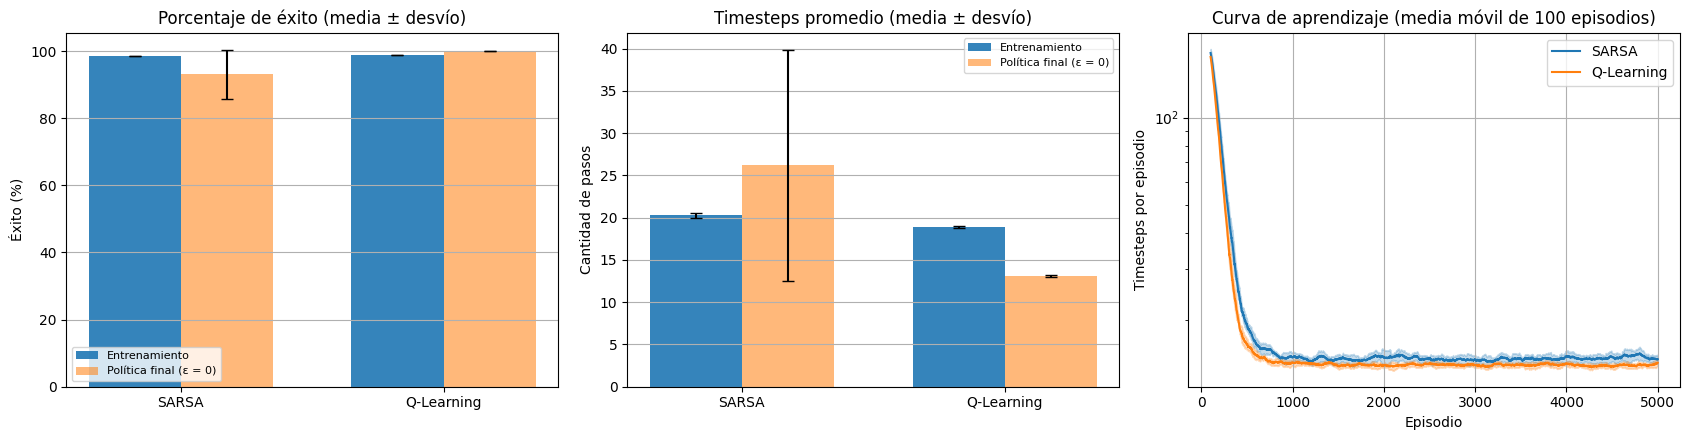

In [29]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
colores = {"SARSA": "tab:blue", "Q-Learning": "tab:orange"}

# --- (1) y (2): barras con media ± desvío (entrenamiento vs. política final)
def barras(ax, col_entrenamiento, col_greedy, titulo, ylabel):
    ancho = 0.35
    for i, (col, etiqueta) in enumerate([(col_entrenamiento, "Entrenamiento"),
                                         (col_greedy, "Política final (ε = 0)")]):
        medias = [resultados_finales.loc[resultados_finales.algoritmo == a, col].mean() for a in algoritmos]
        desvios = [resultados_finales.loc[resultados_finales.algoritmo == a, col].std() for a in algoritmos]
        pos = np.arange(len(algoritmos)) + (i - 0.5) * ancho
        ax.bar(pos, medias, ancho, yerr=desvios, capsize=4, label=etiqueta,
               alpha=0.9 if i == 0 else 0.55)
    ax.set_xticks(np.arange(len(algoritmos)))
    ax.set_xticklabels(algoritmos)
    ax.set_title(titulo)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y")
    ax.legend(fontsize=8)

barras(ejes[0], "porcentaje_exito", "exito_greedy", "Porcentaje de éxito (media ± desvío)", "Éxito (%)")
barras(ejes[1], "promedio_timesteps", "timesteps_greedy", "Timesteps promedio (media ± desvío)", "Cantidad de pasos")

# --- (3): curva de aprendizaje (media móvil de timesteps por episodio)
ventana = 100
for alg in algoritmos:
    suav = np.array([np.convolve(c, np.ones(ventana) / ventana, mode="valid") for c in curvas[alg]])
    media, desvio = suav.mean(axis=0), suav.std(axis=0)
    x = np.arange(len(media)) + ventana
    ejes[2].plot(x, media, label=alg, color=colores[alg])
    ejes[2].fill_between(x, media - desvio, media + desvio, color=colores[alg], alpha=0.25)


ejes[2].set_title(f"Curva de aprendizaje (media móvil de {ventana} episodios)")
ejes[2].set_xlabel("Episodio")
ejes[2].set_ylabel("Timesteps por episodio")
ejes[2].set_yscale("log")
ejes[2].grid(True)
ejes[2].legend()

plt.tight_layout()
plt.show()

## Conclusiones

**Resultado principal.** Con la configuración final (ALPHA = 0.4, GAMMA = 0.99, EPSILON = 0.05, K = 5000) y 10 semillas, **Q-Learning presenta mejores resultados que SARSA** en el entorno Taxi-v3.

| Indicador (media ± desvío, 10 semillas) | SARSA | Q-Learning |
|---|---|---|
| Éxito durante el entrenamiento (%) | 98.50 ± 0.11 | 98.88 ± 0.06 |
| Timesteps promedio durante el entrenamiento | 20.26 ± 0.32 | 18.85 ± 0.11 |
| Éxito de la política final, ε = 0 (%) | 93.14 ± 7.27 | 100.00 ± 0.00 |
| Timesteps de la política final, ε = 0 | 26.18 ± 13.69 | 13.07 ± 0.11 |
| Tiempo de entrenamiento (s) | 2.10 ± 0.46 | 2.60 ± 0.52 |

**Justificación gráfica.**

En la curva de aprendizaje, ambos algoritmos reducen los timesteps por episodio de forma muy rápida durante los primeros ~1.000 episodios, pero Q-Learning se mantiene por debajo de SARSA durante todo el entrenamiento. En las barras, la diferencia es pequeña durante el entrenamiento, pero muy clara en la política final: Q-Learning alcanza 100.00 % de éxito con 13.07 pasos en todas las semillas, mientras que SARSA tiene 93.14 % de éxito, 26.18 pasos y una barra de error mucho mayor.

**Justificación analítica.**
* Durante el entrenamiento la diferencia es estadísticamente significativa, pero pequeña en términos prácticos (0.38 puntos de éxito y 1.41 timesteps).
* En la política final, la diferencia es más grande y también significativa (prueba t de Welch: p = 0.0154 para el éxito y p = 0.0143 para los timesteps). Aquí el éxito de Q-Learning tiene desvío 0, lo que hace que el p-valor del éxito sea aproximado; el resultado se apoya además en el conteo por semillas.
* Q-Learning superó a SARSA en éxito de la política final en 7 de las 10 semillas y empató en las 3 restantes (SARSA también llegó a 100.00 %); nunca perdió.
* Q-Learning es además mucho más estable: su desvío en los timesteps de la política final es 0.11, frente a 13.69 en SARSA.

**Interpretación.**
Q-Learning es off-policy:

Actualiza con el máximo valor del siguiente estado y por eso aprende directamente la política óptima, aunque se comporte con exploración. SARSA es on-policy: su tabla Q incorpora el efecto de las acciones exploratorias (en Taxi, las acciones aleatorias pueden costar −10 por recoger o dejar en un lugar incorrecto). Por eso la política greedy que se extrae de SARSA es más variable entre corridas. Esto es coherente con lo observado en las pruebas de hiperparámetros, donde SARSA fue mucho más sensible a EPSILON que Q-Learning.


**Hiperparámetros y costo computacional.**

Con K = 100 ninguno de los algoritmos logra aprender una política efectiva, mientras que con K = 5000 ambos alcanzan un desempeño elevado. Aumentar a K = 10000 implica un mayor costo computacional con mejoras marginales en los resultados. Los mejores valores evaluados fueron ALPHA = 0.4 y GAMMA = 0.99 para ambos algoritmos, mientras que SARSA mostró un mejor desempeño con un EPSILON bajo (0.05).

En cuanto al costo computacional, SARSA registró un tiempo promedio de entrenamiento de 2.10 ± 0.46 segundos, mientras que Q-Learning obtuvo 2.60 ± 0.52 segundos. Aunque Q-Learning presentó un tiempo de entrenamiento ligeramente mayor, logró mejores resultados en porcentaje de éxito y cantidad de timesteps. Por lo tanto, esta diferencia en el costo computacional no modifica la conclusión de que Q-Learning presentó un mejor desempeño general en el entorno Taxi-v3.

**Limitaciones.**

Los hiperparámetros se ajustaron de a uno por vez y con una sola semilla, por lo que no se descartan interacciones entre ellos; la configuración final se validó con 10 semillas. Los resultados corresponden al entorno Taxi-v3 y no implican que Q-Learning sea siempre superior en otros entornos (por ejemplo, en problemas con penalizaciones graves cerca de la ruta óptima, la prudencia de SARSA puede ser una ventaja).